# designing the scaling and reward #

## 1. generating unscaled data using the same PID set up ##

In [1]:
from physical_pid_data_generation import generate_pid_dataset

df = generate_pid_dataset(
    n_runs=100,
    t_total=100 * 3600,
    dt=30 * 60,
    seed=123,
    trajectory_csv="unscaled_pid_dataset.csv",
)

df.head()

run 1/100
run 2/100
run 3/100
run 4/100
run 5/100
run 6/100
run 7/100
run 8/100
run 9/100
run 10/100
run 11/100
run 12/100
run 13/100
run 14/100
run 15/100
run 16/100
run 17/100
run 18/100
run 19/100
run 20/100
run 21/100
run 22/100
run 23/100
run 24/100
run 25/100
run 26/100
run 27/100
run 28/100
run 29/100
run 30/100
run 31/100
run 32/100
run 33/100
run 34/100
run 35/100
run 36/100
run 37/100
run 38/100
run 39/100
run 40/100
run 41/100
run 42/100
run 43/100
run 44/100
run 45/100
run 46/100
run 47/100
run 48/100
run 49/100
run 50/100
run 51/100
run 52/100
run 53/100
run 54/100
run 55/100
run 56/100
run 57/100
run 58/100
run 59/100
run 60/100
run 61/100
run 62/100
run 63/100
run 64/100
run 65/100
run 66/100
run 67/100
run 68/100
run 69/100
run 70/100
run 71/100
run 72/100
run 73/100
run 74/100
run 75/100
run 76/100
run 77/100
run 78/100
run 79/100
run 80/100
run 81/100
run 82/100
run 83/100
run 84/100
run 85/100
run 86/100
run 87/100
run 88/100
run 89/100
run 90/100
run 91/100
run 92/1

,run_id,step,time_min,A,I,P,R,T,err_P,err_T,int_err_P,int_err_T,f_I,T_c
0,0,0,0.0,559.445903,0.000000,0.094561,0.000000e+00,350.105120,99.905439,-0.105120,0.0,0.000000,2.5,344.199607
1,0,1,30.0,556.679343,1.194664,1.852605,4.774059e-07,348.760463,98.147395,1.239537,0.0,-189.216877,2.5,344.202518
2,0,2,60.0,551.289643,2.285141,5.437567,6.711129e-07,348.372673,94.562433,1.627327,0.0,2041.949007,2.5,344.228912
3,0,3,90.0,545.426484,3.280515,10.425383,8.279905e-07,349.188465,89.574617,0.811535,0.0,4971.137665,2.5,344.258611
4,0,4,120.0,537.766018,4.189081,16.564851,9.726150e-07,349.728284,83.435149,0.271716,0.0,6431.901132,2.5,344.272925


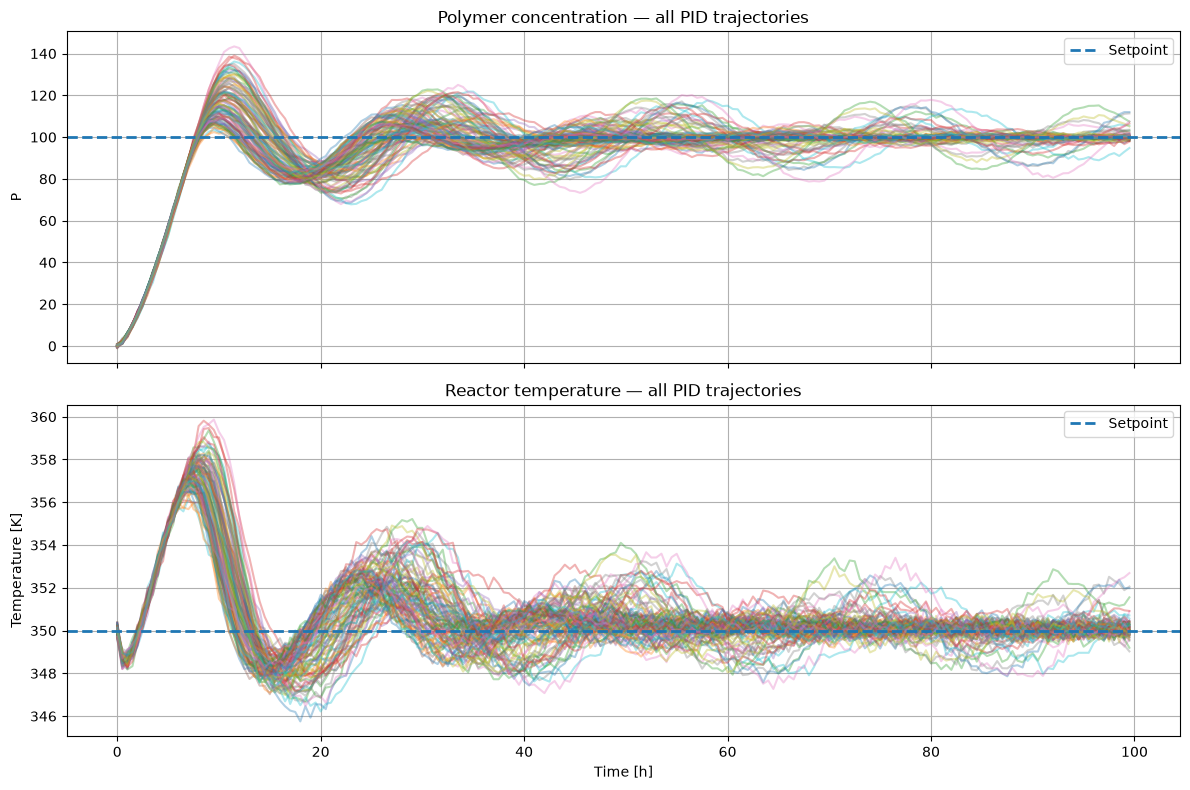

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Plot every PID run
for run_id, run in df.groupby("run_id"):
    axes[0].plot(
        run["time_min"] / 60,
        run["P"],
        alpha=0.35
    )

    axes[1].plot(
        run["time_min"] / 60,
        run["T"],
        alpha=0.35
    )

# Setpoints
axes[0].axhline(
    100,
    linestyle="--",
    linewidth=2,
    label="Setpoint"
)

axes[1].axhline(
    350,
    linestyle="--",
    linewidth=2,
    label="Setpoint"
)

# Polymer
axes[0].set_ylabel("P")
axes[0].set_title("Polymer concentration — all PID trajectories")
axes[0].grid(True)
axes[0].legend()

# Temperature
axes[1].set_xlabel("Time [h]")
axes[1].set_ylabel("Temperature [K]")
axes[1].set_title("Reactor temperature — all PID trajectories")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

In [3]:
from original_hoflon_reward import apply_original_hoflon, rank_pid_runs

hoflon_df = apply_original_hoflon(
    "unscaled_pid_dataset.csv",
    output_csv="original_hoflon_processed.csv",
)

hoflon_df.head()

Saved original-HOFLON processed dataset to: C:\Users\Marco\Documents\HOFLON\env_setup\original_hoflon_processed.csv


,run_id,step,time_min,A,I,P,R,T,err_P,err_T,int_err_P,int_err_T,u_I,u_Tc,reward
0,0,0,0.0,5.594459,0.000000,0.000946,0.000000e+00,1.000300,0.999054,-0.000300,0.0,0.000000,1.0,0.534997,-40.454304
1,0,1,30.0,5.566793,0.011947,0.018526,4.774059e-09,0.996458,0.981474,0.003542,0.0,-0.000541,1.0,0.535021,125.865336
2,0,2,60.0,5.512896,0.022851,0.054376,6.711129e-09,0.995350,0.945624,0.004650,0.0,0.005834,1.0,0.535241,300.671973
3,0,3,90.0,5.454265,0.032805,0.104254,8.279905e-09,0.997681,0.895746,0.002319,0.0,0.014203,1.0,0.535488,419.183768
4,0,4,120.0,5.377660,0.041891,0.165649,9.726150e-09,0.999224,0.834351,0.000776,0.0,0.018377,1.0,0.535608,496.310681


In [6]:
top20 = rank_pid_runs(
    hoflon_df,
    top_n=20,
)

top20

top20_ids = top20["run_id"].tolist()

print(top20_ids)

[29, 41, 71, 33, 69, 10, 61, 36, 79, 5, 38, 24, 96, 50, 18, 0, 72, 76, 94, 40]


In [7]:
from reward_idea_evaluator import evaluate_reward_idea

idea_results = evaluate_reward_idea(
    raw_data="unscaled_pid_dataset.csv",
    run_ids=top20_ids,
    idea_name="Original HOFLON",
    results_csv="reward_trajectory_performance.csv",
)

idea_results

Saved 20 trajectories for 'Original HOFLON' to reward_trajectory_performance.csv


,idea_name,run_id,ise,final_10h_mse
0,Original HOFLON,29,34000.651350,0.295720
1,Original HOFLON,41,34544.534819,0.422727
2,Original HOFLON,71,34581.489894,0.379292
3,Original HOFLON,33,34289.847443,0.193218
4,Original HOFLON,69,34838.619977,0.406051
5,Original HOFLON,10,34460.443458,0.171208
6,Original HOFLON,61,35334.562831,0.492134
7,Original HOFLON,36,34543.550575,0.425344
8,Original HOFLON,79,34563.143623,0.314178
9,Original HOFLON,5,34840.952524,0.403540


## Working on scaling - idea 2 

In [13]:
from idea2_temperature_scaling import (
    apply_idea2_temperature_scaling,
    rank_pid_runs,
)

# Apply Idea 2 scaling + SAME HOFLON reward
idea2_df = apply_idea2_temperature_scaling(
    raw_data="unscaled_pid_dataset.csv",
    output_csv="idea2_processed.csv",
)

idea2_df.head()

Idea 2 temperature scaling:
  T_min                = 345.75434322 K
  T_max                = 359.86501951 K
  T_range              = 14.11067629 K
  T_setpoint_scaled    = 0.30088259
  max_abs_int_T_scaled = 29274.72341404
  u_I range            = [0.000000, 1.000000]
  u_Tc range           = [0.501310, 0.536900]


,run_id,step,time_min,A,I,P,R,T,err_P,err_T,int_err_P,int_err_T,u_I,u_Tc,reward
0,0,0,0.0,5.594459,0.000000,0.000946,0.000000e+00,0.308332,0.999054,-0.007450,0.0,0.000000,1.0,0.534997,-40.734114
1,0,1,30.0,5.566793,0.011947,0.018526,4.774059e-09,0.213039,0.981474,0.087844,0.0,-0.000458,1.0,0.535021,87.237149
2,0,2,60.0,5.512896,0.022851,0.054376,6.711129e-09,0.185557,0.945624,0.115326,0.0,0.004943,1.0,0.535241,272.135802
3,0,3,90.0,5.454265,0.032805,0.104254,8.279905e-09,0.243370,0.895746,0.057512,0.0,0.012034,1.0,0.535488,468.899577
4,0,4,120.0,5.377660,0.041891,0.165649,9.726150e-09,0.281627,0.834351,0.019256,0.0,0.015570,1.0,0.535608,510.952565


In [18]:
idea2_top20 = rank_pid_runs(
    idea2_df,
    top_n=20,
)

idea2_top20_ids = idea2_top20["run_id"].tolist()

print(idea2_top20_ids)

from reward_idea_evaluator import evaluate_reward_idea

idea2_performance = evaluate_reward_idea(
    raw_data="unscaled_pid_dataset.csv",
    run_ids=idea2_top20_ids,
    idea_name="Idea 2 - Normalised T",
    results_csv="reward_trajectory_performance.csv",
)

idea2_performance

[29, 41, 33, 36, 71, 10, 69, 79, 61, 38, 96, 5, 2, 60, 93, 72, 91, 15, 12, 55]
Saved 20 trajectories for 'Idea 2 - Normalised T' to reward_trajectory_performance.csv


,idea_name,run_id,ise,final_10h_mse
0,Idea 2 - Normalised T,29,34000.651350,0.295720
1,Idea 2 - Normalised T,41,34544.534819,0.422727
2,Idea 2 - Normalised T,33,34289.847443,0.193218
3,Idea 2 - Normalised T,36,34543.550575,0.425344
4,Idea 2 - Normalised T,71,34581.489894,0.379292
5,Idea 2 - Normalised T,10,34460.443458,0.171208
6,Idea 2 - Normalised T,69,34838.619977,0.406051
7,Idea 2 - Normalised T,79,34563.143623,0.314178
8,Idea 2 - Normalised T,61,35334.562831,0.492134
9,Idea 2 - Normalised T,38,34446.041038,0.199487


## Idea 3 - -ve mse as reward 

In [23]:
from idea3_mse_reward import (
    apply_idea3_mse_reward,
    rank_pid_runs,
)

# Apply fixed Idea 2 scaling + Idea 3 reward
idea3_df = apply_idea3_mse_reward(
    raw_data="unscaled_pid_dataset.csv",
    output_csv="idea3_mse_processed.csv",
)

# Rank PID runs
idea3_top20 = rank_pid_runs(
    idea3_df,
    top_n=20,
)

idea3_top20

Idea 3: -MSE reward
  T_min             = 345.75434322 K
  T_max             = 359.86501951 K
  T_setpoint_scaled = 0.30088259
  reward            = -(err_P^2 + err_T^2)


,rank,run_id,cumulative_reward
0,1,29,-9.090518
1,2,71,-9.208003
2,3,41,-9.255499
3,4,33,-9.339549
4,5,38,-9.635651
5,6,10,-9.660065
6,7,96,-9.669720
7,8,69,-9.786084
8,9,60,-9.794389
9,10,61,-9.809723


In [24]:
idea3_top20_ids = idea3_top20["run_id"].tolist()

print(idea3_top20_ids)


from reward_idea_evaluator import evaluate_reward_idea

evaluate_reward_idea(
    raw_data="unscaled_pid_dataset.csv",
    run_ids=idea3_top20_ids,
    idea_name="Idea 3 - MSE",
    results_csv="reward_trajectory_performance.csv",
)

[29, 71, 41, 33, 38, 10, 96, 69, 60, 61, 72, 5, 79, 2, 36, 90, 18, 64, 91, 13]
Saved 20 trajectories for 'Idea 3 - MSE' to reward_trajectory_performance.csv


,idea_name,run_id,ise,final_10h_mse
0,Idea 3 - MSE,29,34000.651350,0.295720
1,Idea 3 - MSE,71,34581.489894,0.379292
2,Idea 3 - MSE,41,34544.534819,0.422727
3,Idea 3 - MSE,33,34289.847443,0.193218
4,Idea 3 - MSE,38,34446.041038,0.199487
5,Idea 3 - MSE,10,34460.443458,0.171208
6,Idea 3 - MSE,96,34438.174828,0.294008
7,Idea 3 - MSE,69,34838.619977,0.406051
8,Idea 3 - MSE,60,35887.434875,0.247833
9,Idea 3 - MSE,61,35334.562831,0.492134


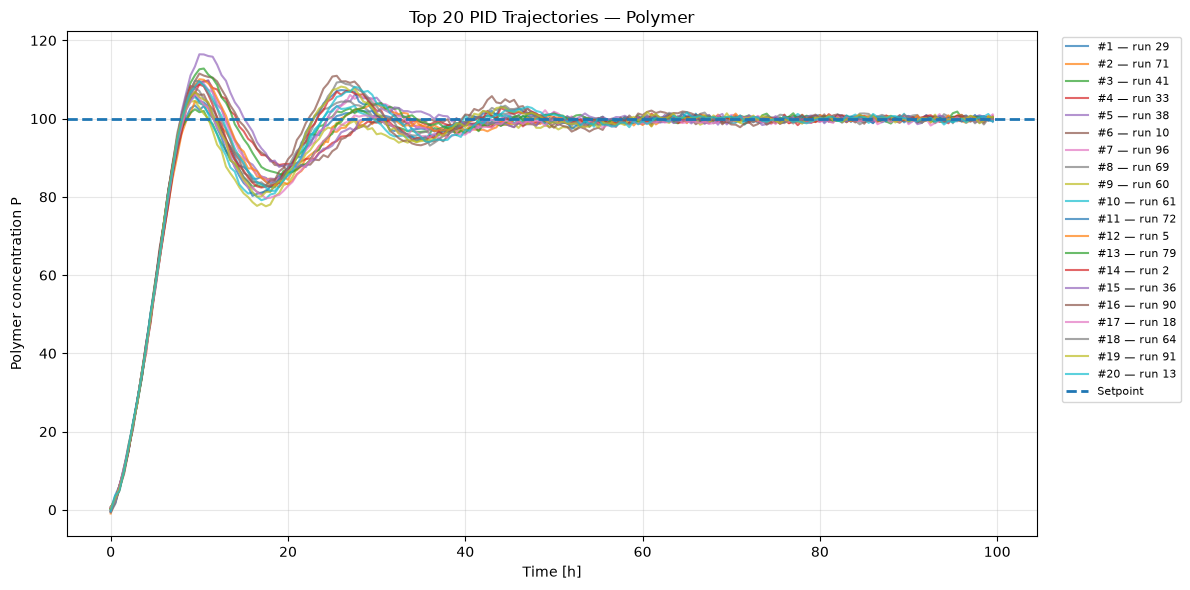

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Choose which top-20 ranking you want to plot
# ---------------------------------------------------------

top20 = idea3_top20
# top20 = idea4_top20   # swap to this for Idea 4

# Original physical PID trajectories
raw_df = pd.read_csv("unscaled_pid_dataset.csv")

top20_ids = top20["run_id"].tolist()


# ---------------------------------------------------------
# Plot P
# ---------------------------------------------------------

plt.figure(figsize=(12, 6))

for rank, run_id in enumerate(top20_ids, start=1):

    run = raw_df[
        raw_df["run_id"] == run_id
    ].sort_values("time_min")

    plt.plot(
        run["time_min"] / 60,
        run["P"],
        alpha=0.7,
        label=f"#{rank} — run {run_id}"
    )

plt.axhline(
    100,
    linestyle="--",
    linewidth=2,
    label="Setpoint"
)

plt.xlabel("Time [h]")
plt.ylabel("Polymer concentration P")
plt.title("Top 20 PID Trajectories — Polymer")

plt.grid(alpha=0.3)

# Legend outside because 20 labels is a lot
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

## Idea 4 

In [25]:
from idea4_mse_change_reward import (
    apply_idea4_mse_change_reward,
    rank_pid_runs,
)

# Apply fixed Idea 2 scaling + Idea 4 reward
idea4_df = apply_idea4_mse_change_reward(
    raw_data="unscaled_pid_dataset.csv",
    output_csv="idea4_mse_change_processed.csv",
)

# Rank PID runs
idea4_top20 = rank_pid_runs(
    idea4_df,
    top_n=20,
)


idea4_top20_ids = idea4_top20["run_id"].tolist()

print(idea4_top20_ids)

from reward_idea_evaluator import evaluate_reward_idea

evaluate_reward_idea(
    raw_data="unscaled_pid_dataset.csv",
    run_ids=idea4_top20_ids,
    idea_name="Idea 4 - Change in MSE",
    results_csv="reward_trajectory_performance.csv",
)

Idea 4: change-in-MSE reward
  T_min             = 345.75434322 K
  T_max             = 359.86501951 K
  T_setpoint_scaled = 0.30088259
  reward            = E_t - E_(t+1)
  final row/run     = dropped
[97, 71, 45, 15, 24, 74, 66, 69, 28, 9, 64, 36, 84, 19, 2, 21, 1, 94, 20, 48]
Saved 20 trajectories for 'Idea 4 - Change in MSE' to reward_trajectory_performance.csv


,idea_name,run_id,ise,final_10h_mse
0,Idea 4 - Change in MSE,97,40775.143758,3.373612
1,Idea 4 - Change in MSE,71,34581.489894,0.379292
2,Idea 4 - Change in MSE,45,36685.048669,0.244300
3,Idea 4 - Change in MSE,15,35294.712582,0.298886
4,Idea 4 - Change in MSE,24,35222.807329,0.457608
5,Idea 4 - Change in MSE,74,35679.726927,0.314434
6,Idea 4 - Change in MSE,66,35912.284234,0.255290
7,Idea 4 - Change in MSE,69,34838.619977,0.406051
8,Idea 4 - Change in MSE,28,40129.708785,1.283537
9,Idea 4 - Change in MSE,9,35769.778252,0.479363


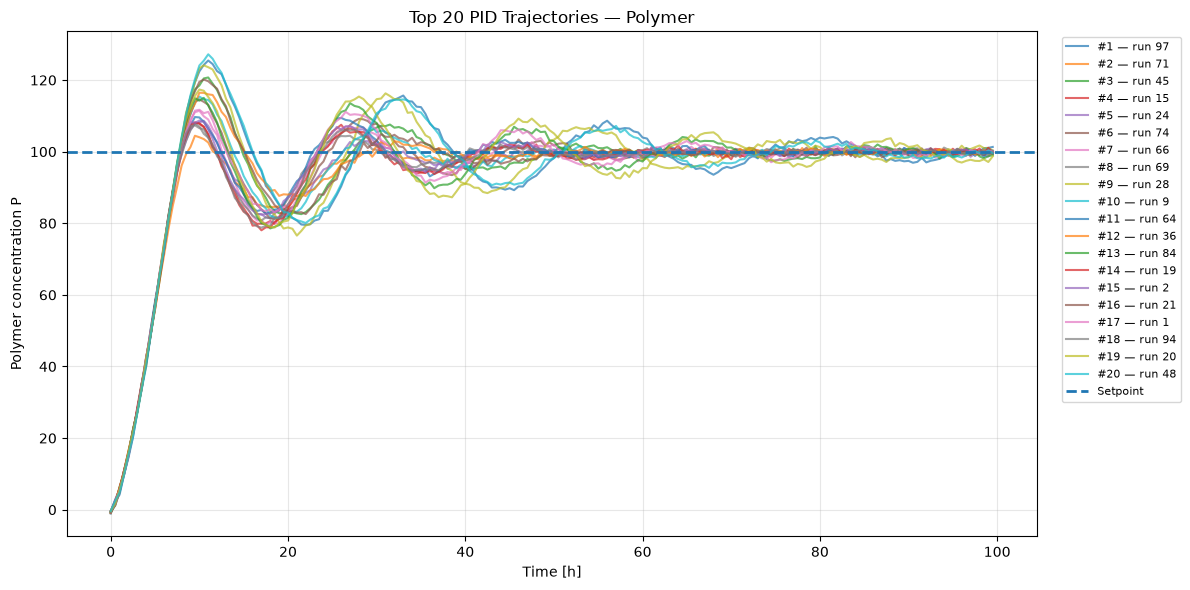

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Choose which top-20 ranking you want to plot
# ---------------------------------------------------------

top20 = idea4_top20   # swap to this for Idea 4

# Original physical PID trajectories
raw_df = pd.read_csv("unscaled_pid_dataset.csv")

top20_ids = top20["run_id"].tolist()


# ---------------------------------------------------------
# Plot P
# ---------------------------------------------------------

plt.figure(figsize=(12, 6))

for rank, run_id in enumerate(top20_ids, start=1):

    run = raw_df[
        raw_df["run_id"] == run_id
    ].sort_values("time_min")

    plt.plot(
        run["time_min"] / 60,
        run["P"],
        alpha=0.7,
        label=f"#{rank} — run {run_id}"
    )

plt.axhline(
    100,
    linestyle="--",
    linewidth=2,
    label="Setpoint"
)

plt.xlabel("Time [h]")
plt.ylabel("Polymer concentration P")
plt.title("Top 20 PID Trajectories — Polymer")

plt.grid(alpha=0.3)

# Legend outside because 20 labels is a lot
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

## Summary plot 

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load evaluation results
results = pd.read_csv("reward_trajectory_performance.csv")

ideas = results["idea_name"].unique()
x = np.arange(len(ideas))

rng = np.random.default_rng(123)

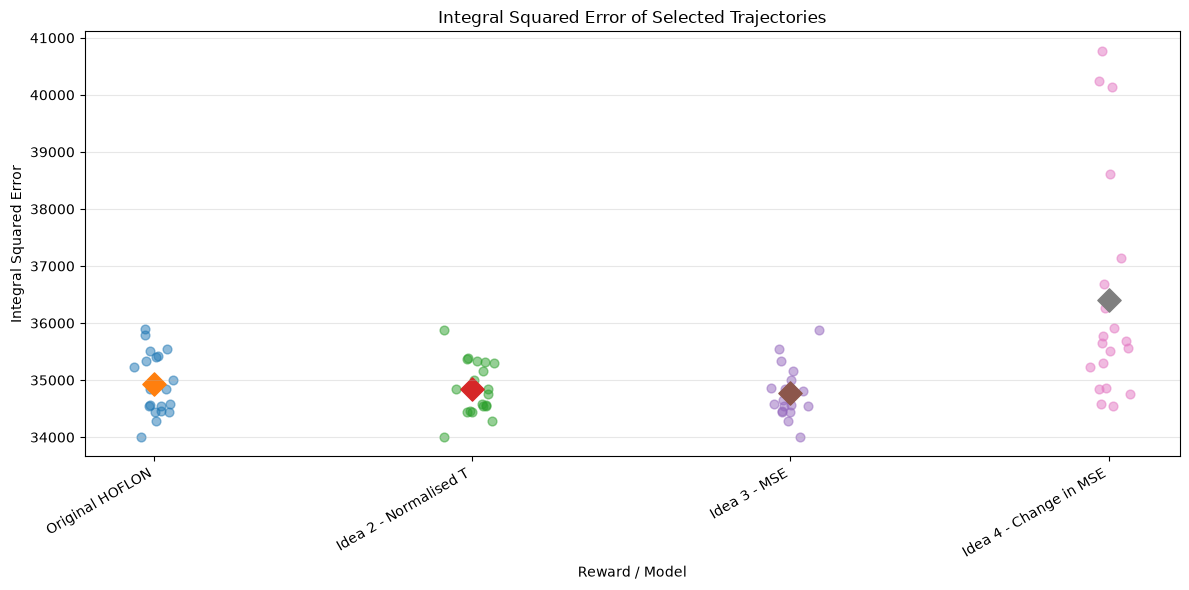

In [27]:
plt.figure(figsize=(12, 6))

for i, idea in enumerate(ideas):

    group = results[
        results["idea_name"] == idea
    ]

    # Slight jitter so the 20 trajectories can be seen
    jitter = rng.normal(0, 0.04, len(group))

    plt.scatter(
        x[i] + jitter,
        group["ise"],
        alpha=0.5,
        s=40
    )

    # Mean
    plt.scatter(
        x[i],
        group["ise"].mean(),
        marker="D",
        s=140
    )

plt.xticks(
    x,
    ideas,
    rotation=30,
    ha="right"
)

plt.xlabel("Reward / Model")
plt.ylabel("Integral Squared Error")
plt.title("Integral Squared Error of Selected Trajectories")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
plt.figure(figsize=(12, 6))

for i, idea in enumerate(ideas):

    group = results[
        results["idea_name"] == idea
    ]

    jitter = rng.normal(0, 0.04, len(group))

    plt.scatter(
        x[i] + jitter,
        group["final_10h_mse"],
        alpha=0.5,
        s=40
    )

    # Mean
    plt.scatter(
        x[i],
        group["final_10h_mse"].mean(),
        marker="D",
        s=140
    )

plt.xticks(
    x,
    ideas,
    rotation=30,
    ha="right"
)

plt.xlabel("Reward / Model")
plt.ylabel("Final 10-hour MSE")
plt.title("Final 10-hour MSE of Selected Trajectories")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'ideas' is not defined

<Figure size 1200x600 with 0 Axes>

Write up notes 


- immediately changing the scaling has reflected a lower error in both ise and mse 

## Weighted BC test ## 

- scale weight based on min-max reward
-train a bc actor on this 

In [1]:
from train_weighted_bc import train_weighted_bc

model, history = train_weighted_bc(
    dataset_path="idea3_mse_processed.csv",
    output_path="idea3_bc_actor.pth",
)

Epoch   1/100 | weighted BC loss = 0.01269190
Epoch  10/100 | weighted BC loss = 0.00265982
Epoch  20/100 | weighted BC loss = 0.00168804
Epoch  30/100 | weighted BC loss = 0.00107097
Epoch  40/100 | weighted BC loss = 0.00076658
Epoch  50/100 | weighted BC loss = 0.00067280
Epoch  60/100 | weighted BC loss = 0.00059678
Epoch  70/100 | weighted BC loss = 0.00055838
Epoch  80/100 | weighted BC loss = 0.00048731
Epoch  90/100 | weighted BC loss = 0.00052264
Epoch 100/100 | weighted BC loss = 0.00045055

Training rows: 20000
Reward range: [-1.02158, -5.57783e-08]
Weight range: [0, 1]
Saved actor to: C:\Users\Marco\Documents\HOFLON\env_setup\idea3_bc_actor.pth


In [2]:
from train_weighted_bc import train_weighted_bc

model, history = train_weighted_bc(
    dataset_path="idea4_mse_change_processed.csv",
    output_path="idea4_bc_actor.pth",
)

Epoch   1/100 | weighted BC loss = 0.01696684
Epoch  10/100 | weighted BC loss = 0.00295242
Epoch  20/100 | weighted BC loss = 0.00202089
Epoch  30/100 | weighted BC loss = 0.00130712
Epoch  40/100 | weighted BC loss = 0.00101998
Epoch  50/100 | weighted BC loss = 0.00084878
Epoch  60/100 | weighted BC loss = 0.00077942
Epoch  70/100 | weighted BC loss = 0.00073027
Epoch  80/100 | weighted BC loss = 0.00068806
Epoch  90/100 | weighted BC loss = 0.00066098
Epoch 100/100 | weighted BC loss = 0.00061746

Training rows: 19900
Reward range: [-0.127431, 0.127575]
Weight range: [0, 1]
Saved actor to: C:\Users\Marco\Documents\HOFLON\env_setup\idea4_bc_actor.pth


In [ ]:
import importlib
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyTorch 2.14 compatibility fix for your installation
if not hasattr(torch, "_utils"):
    torch._utils = importlib.import_module("torch._utils")

from train_weighted_bc import load_weighted_bc
from benchmark.poly_reactor_env import PolymerisationIdea2Env


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

idea3_actor = load_weighted_bc(
    "idea3_bc_actor.pth",
    device=DEVICE,
)

idea4_actor = load_weighted_bc(
    "idea4_bc_actor.pth",
    device=DEVICE,
)

idea3_actor.eval()
idea4_actor.eval()

Device: cuda


WeightedBCActor(
  (net): Sequential(
    (0): Linear(in_features=9, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=2, bias=True)
    (5): Sigmoid()
  )
)

In [4]:
def test_actor(
    actor,
    model_name,
    seed=123,
    t_total=100 * 3600,
    dt=30 * 60,
):
    """
    Run one BC actor closed-loop in poly_reactor_env.

    Actor receives:
        scaled 9D observation

    Actor outputs:
        [u_I, u_Tc] in [0,1]

    Environment internally:
        converts action to physical units
        integrates physical ODE
        returns next scaled observation
    """

    env = PolymerisationIdea2Env(
        raw_pid_data="unscaled_pid_dataset.csv",
        dt=dt,
        t_total=t_total,
        seed=seed,
    )

    obs, info = env.reset(seed=seed)

    actor_device = next(actor.parameters()).device

    rows = []

    # Initial physical state
    rows.append({
        "time_min": info["time_min"],
        "P": info["P_true"],
        "T": info["T_true"],
        "u_I": np.nan,
        "u_Tc": np.nan,
        "f_I": np.nan,
        "T_c": np.nan,
    })

    done = False

    while not done:

        obs_tensor = torch.tensor(
            obs,
            dtype=torch.float32,
            device=actor_device,
        ).unsqueeze(0)

        with torch.no_grad():
            action = actor(obs_tensor).cpu().numpy()[0]

        next_obs, reward, terminated, truncated, info = env.step(action)

        rows.append({
            "time_min": info["time_min"],

            # Use true physical state for evaluation plots
            "P": info["P_true"],
            "T": info["T_true"],

            # Scaled actor outputs
            "u_I": info["u_I"],
            "u_Tc": info["u_Tc"],

            # Physical actuator values
            "f_I": info["f_I"],
            "T_c": info["T_c"],
        })

        obs = next_obs
        done = terminated or truncated

    df = pd.DataFrame(rows)

    df["model"] = model_name

    return df

In [5]:
idea3_traj = test_actor(
    idea3_actor,
    model_name="Idea 3 Weighted BC",
    seed=123,
)

idea4_traj = test_actor(
    idea4_actor,
    model_name="Idea 4 Weighted BC",
    seed=123,
)

print("Idea 3:", idea3_traj.shape)
print("Idea 4:", idea4_traj.shape)

Idea 3: (201, 8)
Idea 4: (201, 8)


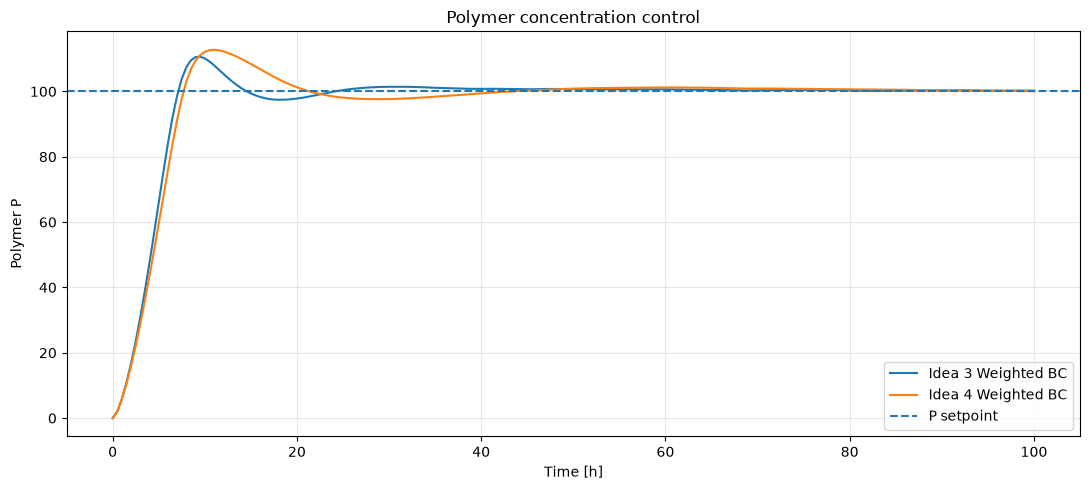

In [6]:
plt.figure(figsize=(11, 5))

plt.plot(
    idea3_traj["time_min"] / 60,
    idea3_traj["P"],
    label="Idea 3 Weighted BC",
)

plt.plot(
    idea4_traj["time_min"] / 60,
    idea4_traj["P"],
    label="Idea 4 Weighted BC",
)

plt.axhline(
    100,
    linestyle="--",
    label="P setpoint",
)

plt.xlabel("Time [h]")
plt.ylabel("Polymer P")
plt.title("Polymer concentration control")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

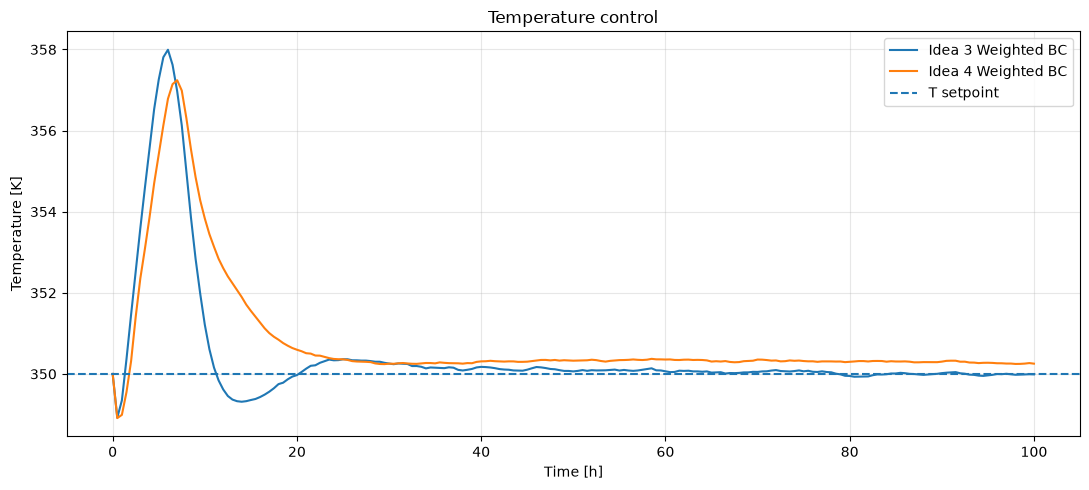

In [7]:
plt.figure(figsize=(11, 5))

plt.plot(
    idea3_traj["time_min"] / 60,
    idea3_traj["T"],
    label="Idea 3 Weighted BC",
)

plt.plot(
    idea4_traj["time_min"] / 60,
    idea4_traj["T"],
    label="Idea 4 Weighted BC",
)

plt.axhline(
    350,
    linestyle="--",
    label="T setpoint",
)

plt.xlabel("Time [h]")
plt.ylabel("Temperature [K]")
plt.title("Temperature control")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
def evaluate_trajectory(df):

    time_h = df["time_min"].to_numpy() / 60

    P = df["P"].to_numpy()
    T = df["T"].to_numpy()

    squared_error = (
        (P - 100) ** 2
        + (T - 350) ** 2
    )

    ise = np.trapezoid(
        squared_error,
        time_h,
    )

    final_time = time_h[-1]

    final_mask = (
        time_h >= final_time - 10
    )

    final_10h_mse = np.mean(
        squared_error[final_mask]
    )

    return {
        "ISE": ise,
        "Final 10h MSE": final_10h_mse,
    }


results = pd.DataFrame({
    "Idea 3 Weighted BC": evaluate_trajectory(idea3_traj),
    "Idea 4 Weighted BC": evaluate_trajectory(idea4_traj),
}).T

results

,ISE,Final 10h MSE
Idea 3 Weighted BC,30367.660201,0.066904
Idea 4 Weighted BC,32769.517575,0.136186


In [9]:
import pandas as pd
import numpy as np

RESULTS_CSV = "reward_trajectory_performance.csv"


def trajectory_metrics(df):

    time_h = df["time_min"].to_numpy() / 60.0
    P = df["P"].to_numpy()
    T = df["T"].to_numpy()

    error_sq = (
        (P - 100.0) ** 2
        + (T - 350.0) ** 2
    )

    ise = np.trapezoid(
        error_sq,
        time_h,
    )

    final_mask = (
        time_h >= time_h[-1] - 10.0
    )

    final_10h_mse = np.mean(
        error_sq[final_mask]
    )

    return ise, final_10h_mse


# --------------------------------------------------
# Calculate BC performance
# --------------------------------------------------

idea3_ise, idea3_mse = trajectory_metrics(
    idea3_traj
)

idea4_ise, idea4_mse = trajectory_metrics(
    idea4_traj
)


new_results = pd.DataFrame([
    {
        "idea_name": "Idea 3 - Weighted BC",
        "run_id": "BC_seed_123",
        "ise": idea3_ise,
        "final_10h_mse": idea3_mse,
    },
    {
        "idea_name": "Idea 4 - Weighted BC",
        "run_id": "BC_seed_123",
        "ise": idea4_ise,
        "final_10h_mse": idea4_mse,
    },
])


# --------------------------------------------------
# Load existing comparison file
# --------------------------------------------------

results = pd.read_csv(
    RESULTS_CSV
)


# Remove previous versions of these BC results
# so rerunning the cell doesn't duplicate them.
bc_names = new_results[
    "idea_name"
].unique()

results = results[
    ~results["idea_name"].isin(bc_names)
]


# Append
results = pd.concat(
    [results, new_results],
    ignore_index=True,
)


results.to_csv(
    RESULTS_CSV,
    index=False,
)

display(results)

,idea_name,run_id,ise,final_10h_mse
0,Original HOFLON,29,34000.651350,0.295720
1,Original HOFLON,41,34544.534819,0.422727
2,Original HOFLON,71,34581.489894,0.379292
3,Original HOFLON,33,34289.847443,0.193218
4,Original HOFLON,69,34838.619977,0.406051
...,...,...,...,...
77,Idea 4 - Change in MSE,94,35512.160826,0.219549
78,Idea 4 - Change in MSE,20,38614.282533,3.645165
79,Idea 4 - Change in MSE,48,40235.969719,1.666755
80,Idea 3 - Weighted BC,BC_seed_123,30367.660201,0.066904


In [12]:
from train_hybrid_bc_sweep import train_hybrid_sweep

models, histories, datasets = train_hybrid_sweep(
    base_dataset="idea3_mse_processed.csv",
)

Absolute component range: (0.0, 1.0)
Change component range: (0.0, 1.0)
Saved lambda=0.05 dataset -> hybrid_reward_datasets\hybrid_lambda_0p05.csv
Saved lambda=0.1 dataset -> hybrid_reward_datasets\hybrid_lambda_0p1.csv
Saved lambda=0.2 dataset -> hybrid_reward_datasets\hybrid_lambda_0p2.csv
Saved lambda=0.5 dataset -> hybrid_reward_datasets\hybrid_lambda_0p5.csv

Training hybrid weighted BC | lambda = 0.05
Epoch   1/100 | weighted BC loss = 0.01309419
Epoch  10/100 | weighted BC loss = 0.00273714
Epoch  20/100 | weighted BC loss = 0.00180433
Epoch  30/100 | weighted BC loss = 0.00111529
Epoch  40/100 | weighted BC loss = 0.00085862
Epoch  50/100 | weighted BC loss = 0.00071198
Epoch  60/100 | weighted BC loss = 0.00063122
Epoch  70/100 | weighted BC loss = 0.00058043
Epoch  80/100 | weighted BC loss = 0.00053445
Epoch  90/100 | weighted BC loss = 0.00054356
Epoch 100/100 | weighted BC loss = 0.00047671

Training rows: 19900
Reward range: [0.0244728, 1.02645]
Weight range: [0, 1]
Saved

In [ ]:
import importlib
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Compatibility with your PyTorch installation
if not hasattr(torch, "_utils"):
    torch._utils = importlib.import_module("torch._utils")

from train_weighted_bc import load_weighted_bc
from benchmark.poly_reactor_env import PolymerisationIdea2Env


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)


LAMBDAS = [
    0.05,
    0.10,
    0.20,
    0.50,
]


MODEL_PATHS = {
    0.05: "hybrid_bc_models/hybrid_bc_lambda_0p05.pth",
    0.10: "hybrid_bc_models/hybrid_bc_lambda_0p1.pth",
    0.20: "hybrid_bc_models/hybrid_bc_lambda_0p2.pth",
    0.50: "hybrid_bc_models/hybrid_bc_lambda_0p5.pth",
}


actors = {
    lam: load_weighted_bc(
        path,
        device=DEVICE,
    )
    for lam, path in MODEL_PATHS.items()
}

print("Loaded:", list(actors.keys()))

Device: cuda
Loaded: [0.05, 0.1, 0.2, 0.5]


In [14]:
def rollout_actor(
    actor,
    seed=123,
    dt=30 * 60,
    t_total=100 * 3600,
):

    env = PolymerisationIdea2Env(
        raw_pid_data="unscaled_pid_dataset.csv",
        dt=dt,
        t_total=t_total,
        seed=seed,
    )

    obs, info = env.reset(seed=seed)

    device = next(actor.parameters()).device

    rows = [{
        "time_min": info["time_min"],
        "P": info["P_true"],
        "T": info["T_true"],
        "u_I": np.nan,
        "u_Tc": np.nan,
        "f_I": np.nan,
        "T_c": np.nan,
    }]

    done = False

    while not done:

        obs_tensor = torch.tensor(
            obs,
            dtype=torch.float32,
            device=device,
        ).unsqueeze(0)

        with torch.no_grad():
            action = (
                actor(obs_tensor)
                .cpu()
                .numpy()[0]
            )

        obs, reward, terminated, truncated, info = env.step(
            action
        )

        rows.append({
            "time_min": info["time_min"],
            "P": info["P_true"],
            "T": info["T_true"],

            "u_I": info["u_I"],
            "u_Tc": info["u_Tc"],

            "f_I": info["f_I"],
            "T_c": info["T_c"],
        })

        done = terminated or truncated

    return pd.DataFrame(rows)

In [15]:
trajectories = {}

for lam, actor in actors.items():

    print(f"Testing lambda = {lam}")

    trajectories[lam] = rollout_actor(
        actor,
        seed=123,
    )

print("Finished all rollouts.")

Testing lambda = 0.05
Testing lambda = 0.1
Testing lambda = 0.2
Testing lambda = 0.5
Finished all rollouts.


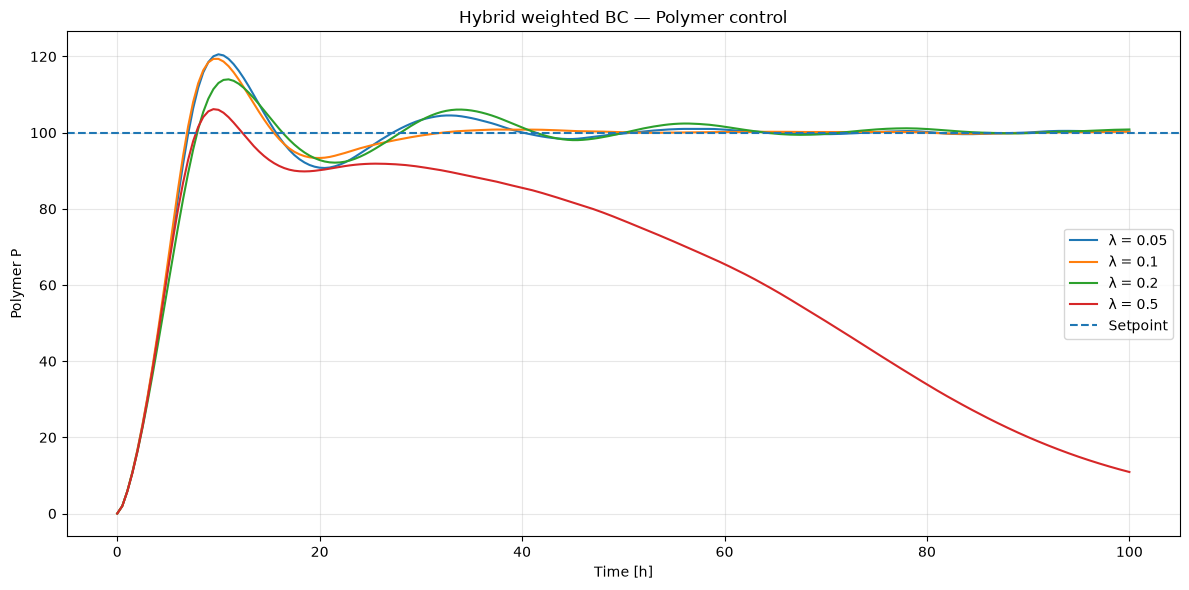

In [19]:
plt.figure(figsize=(12, 6))

for lam, df in trajectories.items():

    plt.plot(
        df["time_min"] / 60,
        df["P"],
        label=f"λ = {lam}",
    )

plt.axhline(
    100,
    linestyle="--",
    label="Setpoint",
)

plt.xlabel("Time [h]")
plt.ylabel("Polymer P")
plt.title("Hybrid weighted BC — Polymer control")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

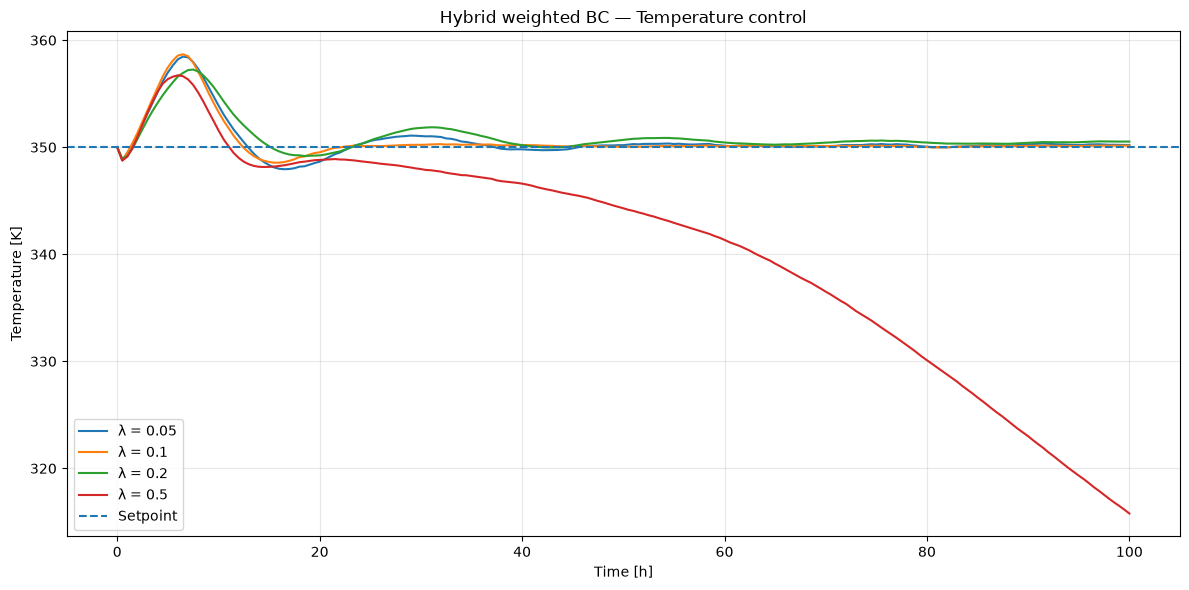

In [20]:
plt.figure(figsize=(12, 6))

for lam, df in trajectories.items():

    plt.plot(
        df["time_min"] / 60,
        df["T"],
        label=f"λ = {lam}",
    )

plt.axhline(
    350,
    linestyle="--",
    label="Setpoint",
)

plt.xlabel("Time [h]")
plt.ylabel("Temperature [K]")
plt.title("Hybrid weighted BC — Temperature control")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
def trajectory_metrics(df):

    time_h = (
        df["time_min"].to_numpy()
        / 60.0
    )

    P = df["P"].to_numpy()
    T = df["T"].to_numpy()

    error_sq = (
        (P - 100.0) ** 2
        + (T - 350.0) ** 2
    )

    ise = np.trapezoid(
        error_sq,
        time_h,
    )

    final_mask = (
        time_h
        >= time_h[-1] - 10.0
    )

    final_10h_mse = np.mean(
        error_sq[final_mask]
    )

    return ise, final_10h_mse


summary = []

for lam, df in trajectories.items():

    ise, mse = trajectory_metrics(df)

    summary.append({
        "lambda": lam,
        "ise": ise,
        "final_10h_mse": mse,
    })


summary_df = pd.DataFrame(summary)

display(summary_df)

,lambda,ise,final_10h_mse
0,0.05,32796.492202,0.216094
1,0.10,31841.250707,0.040486
2,0.20,33123.267617,0.490479
3,0.50,242316.677848,8158.753619


In [17]:
RESULTS_CSV = "reward_trajectory_performance.csv"


new_rows = []

for lam, df in trajectories.items():

    ise, mse = trajectory_metrics(df)

    new_rows.append({
        "idea_name": f"Hybrid BC λ={lam}",
        "run_id": "BC_seed_123",
        "ise": ise,
        "final_10h_mse": mse,
    })


new_results = pd.DataFrame(
    new_rows
)


results = pd.read_csv(
    RESULTS_CSV
)


# Prevent duplicates when rerunning notebook
names = new_results[
    "idea_name"
].unique()

results = results[
    ~results["idea_name"].isin(names)
]


results = pd.concat(
    [
        results,
        new_results,
    ],
    ignore_index=True,
)


results.to_csv(
    RESULTS_CSV,
    index=False,
)

display(results.tail(10))

,idea_name,run_id,ise,final_10h_mse
76,Idea 4 - Change in MSE,1,35652.155005,0.844747
77,Idea 4 - Change in MSE,94,35512.160826,0.219549
78,Idea 4 - Change in MSE,20,38614.282533,3.645165
79,Idea 4 - Change in MSE,48,40235.969719,1.666755
80,Idea 3 - Weighted BC,BC_seed_123,30367.660201,0.066904
81,Idea 4 - Weighted BC,BC_seed_123,32769.517575,0.136186
82,Hybrid BC λ=0.05,BC_seed_123,32796.492202,0.216094
83,Hybrid BC λ=0.1,BC_seed_123,31841.250707,0.040486
84,Hybrid BC λ=0.2,BC_seed_123,33123.267617,0.490479
85,Hybrid BC λ=0.5,BC_seed_123,242316.677848,8158.753619


# End plots

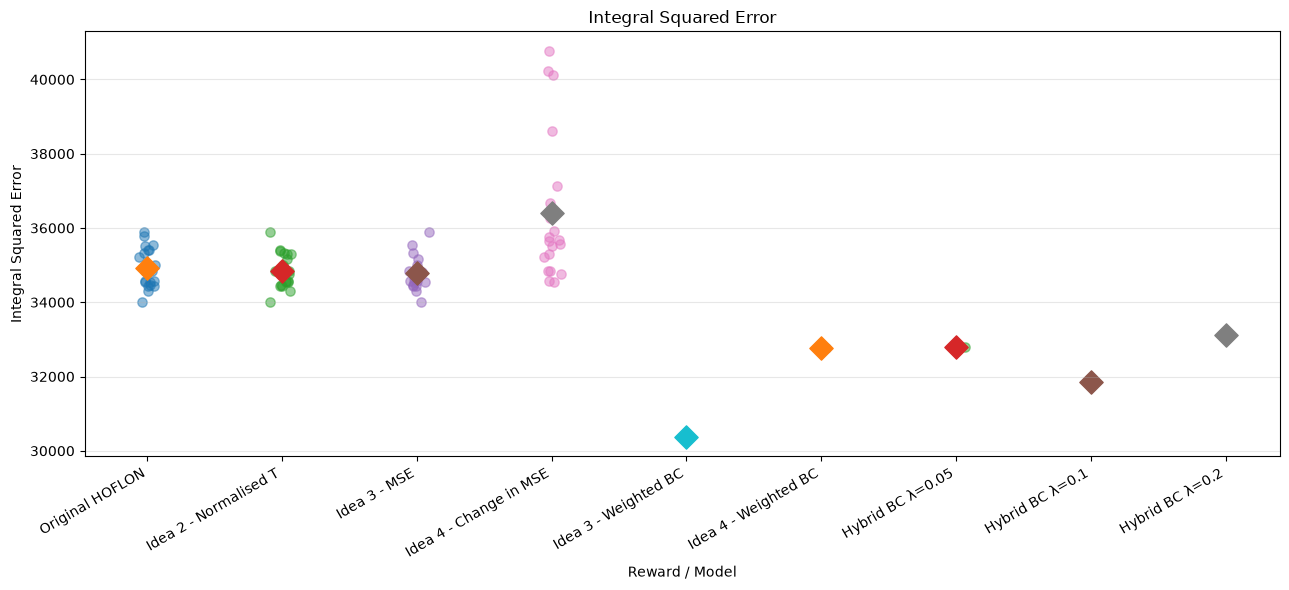

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


results = pd.read_csv(
    "reward_trajectory_performance.csv"
)

ideas = results[
    "idea_name"
].unique()

x = np.arange(
    len(ideas)
)

rng = np.random.default_rng(123)


plt.figure(figsize=(13, 6))


for i, idea in enumerate(ideas):

    group = results[
        results["idea_name"] == idea
    ]

    jitter = rng.normal(
        0,
        0.04,
        len(group),
    )

    plt.scatter(
        x[i] + jitter,
        group["ise"],
        alpha=0.5,
        s=45,
    )

    plt.scatter(
        x[i],
        group["ise"].mean(),
        marker="D",
        s=140,
    )


plt.xticks(
    x,
    ideas,
    rotation=30,
    ha="right",
)

plt.xlabel("Reward / Model")
plt.ylabel("Integral Squared Error")
plt.title("Integral Squared Error")

plt.grid(
    axis="y",
    alpha=0.3,
)

plt.tight_layout()
plt.show()